# 2 Oct - lidar and slam on robot 10

Notes from the day and a look at the maze recording.

Needs only `pip install rosbags numpy matplotlib`, no ROS. The bag isn't in the repo (5 MB),
copy `maze_20261002_155543` from `~/rosbag_dir` on the Pi to `~/rosbag_dir` here, or change `BAG` below.

## What got done

- lidar launch file, with a 180 deg static transform because the lidar is mounted backwards
- slam_toolbox in the bringup, running in the robot namespace (`/robot_10`)
- tf and odom from the robot didn't come through, fixed by using cyclonedds like the robot
  (see `scripts/env.sh`)
- tested slam settings, because with the robot standing still most of the far part of the map
  stayed unknown
- recorded a run through the maze, 4.5 min

In [1]:
import math
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from rosbags.highlevel import AnyReader

BAG = Path.home() / "rosbag_dir" / "maze_20261002_155543"

pose = None
path = []
scans = []  # (robot pose at that time, scan)

# reading the bag like in the rosbags docs: https://ternaris.gitlab.io/rosbags/topics/highlevel.html
with AnyReader([BAG]) as reader:
    print(f"{reader.duration / 1e9:.0f} s")
    for conn in reader.connections:
        print(conn.topic, conn.msgcount)

    for conn, t, raw in reader.messages():
        msg = reader.deserialize(raw, conn.msgtype)
        if conn.topic == "/robot_10/odom":
            q = msg.pose.pose.orientation
            yaw = math.atan2(2 * (q.w * q.z + q.x * q.y), 1 - 2 * (q.y**2 + q.z**2))
            pose = (msg.pose.pose.position.x, msg.pose.pose.position.y, yaw)
            path.append(pose[:2])
        elif conn.topic == "/robot_10/scan" and pose is not None:
            scans.append((pose, msg))

271 s
/robot_10/odom 5413
/robot_10/scan 2211
/robot_10/tf 18950
/robot_10/tf_static 2


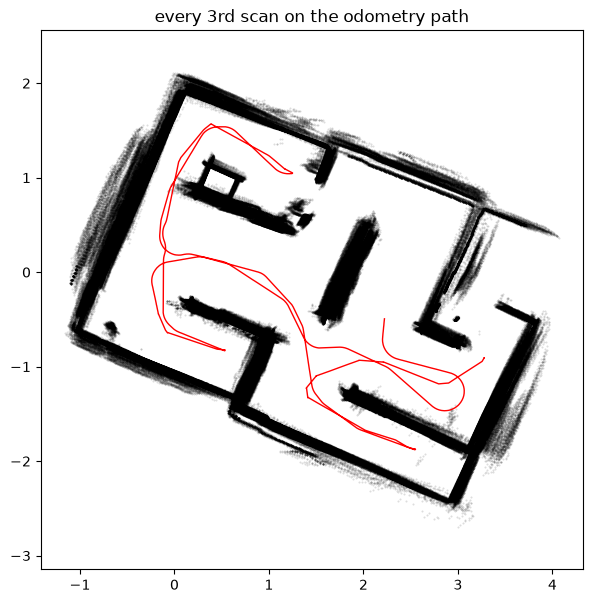

In [2]:
xs, ys = [], []
for (x, y, yaw), scan in scans[::3]:
    r = np.array(scan.ranges)
    # +pi because the lidar is mounted backwards, same as the static transform
    a = scan.angle_min + np.arange(len(r)) * scan.angle_increment + math.pi + yaw
    ok = np.isfinite(r) & (r > scan.range_min)
    xs.extend(x + r[ok] * np.cos(a[ok]))
    ys.extend(y + r[ok] * np.sin(a[ok]))

path = np.array(path)
plt.figure(figsize=(7, 7))
plt.scatter(xs, ys, s=0.2, c="k", alpha=0.15)
plt.plot(path[:, 0], path[:, 1], "r-", lw=1)
plt.axis("equal")
plt.title("every 3rd scan on the odometry path")
plt.show()

Odometry only, no scan matching, so the walls get thicker where it drifts. The slam map itself
wasn't recorded.

## slam settings test

In the first config (minimum travel 0.2 m / 0.2 rad) slam only takes a new scan after the
robot has moved, see `minimum_travel_distance` in the
[slam_toolbox readme](https://github.com/SteveMacenski/slam_toolbox/blob/2.8.4/README.md).
So while the robot stands still slam uses only one scan. Tested by replaying one saved scan to
slam_toolbox with a fixed pose, with 4 configs. Numbers are % of the cells the scan
sees that are still unknown in the map:

| config | travel | min_pass_through | 0-1 m | 1-2 m | 2-3 m | 3-4 m |
| --- | --- | --- | --- | --- | --- | --- |
| A | 0.2 | 2 | 3.3 | 17.8 | 79.7 | 95.7 |
| B | 0.2 | 1 | 2.2 | 9.1 | 33.3 | 51.9 |
| C | 0.0 | 2 | 1.0 | 4.7 | 9.8 | 15.9 |
| D | 0.0 | 1 | 1.0 | 4.7 | 9.8 | 15.9 |

Travel 0 fixes most of it, and min_pass_through 1 adds nothing on top (D is the same as C), so
only the travel thresholds were changed (both 0 now), min_pass_through stays 2.

## Known issues

- the settings test used one scan and a fixed pose, not a driving robot